# Annealing, replica exchange and proximal latent learning
These workflows solve distinct tasks. Temperature annealing changes $e^{-U/T}$; noise annealing uses $\nabla\log p_\sigma$ of a smoothed density; fixed-temperature MALA replicas exchange states with an MH ratio. Proximal interacting methods instead learn a shared parameter with latent particles. [R08](../docs/references.md#r08), [R09](../docs/references.md#r09), [R10](../docs/references.md#r10).

In [1]:
import os, json, time, platform
from pathlib import Path
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from lafa import samplers
from lafa.problems import Gaussian, GaussianMixture2D, Banana2D

torch.set_num_threads(1)
device = torch.device(os.environ.get('LAFA_DEVICE', 'cpu'))
if device.type == 'cuda' and not torch.cuda.is_available():
    raise RuntimeError('LAFA_DEVICE=cuda requested, but CUDA is unavailable')
dtype, seed = torch.float64, 2026
quick = os.environ.get('LAFA_QUICK', '1') == '1'
torch.manual_seed(seed)
def gen(offset=0):
    return torch.Generator(device=device).manual_seed(seed + offset)
def tensor(x): return torch.as_tensor(x, device=device, dtype=dtype)
def cpu(x): return x.detach().cpu().numpy()
def sync():
    if device.type == 'cuda': torch.cuda.synchronize(device)
def table(rows):
    keys = list(dict.fromkeys(k for row in rows for k in row))
    display(Markdown('| ' + ' | '.join(keys) + ' |\n|' + '|'.join(['---']*len(keys)) + '|\n' +
        '\n'.join('| ' + ' | '.join(f'{r[k]:.4g}' if isinstance(r.get(k),float) else str(r.get(k, '—')) for k in keys) + ' |' for r in rows)))
def contour(ax, target, bounds=(-5,5,-5,5)):
    a=torch.linspace(bounds[0],bounds[1],100,device=device,dtype=dtype)
    b=torch.linspace(bounds[2],bounds[3],100,device=device,dtype=dtype)
    xx,yy=torch.meshgrid(a,b,indexing='xy')
    with torch.no_grad(): u=target(torch.stack((xx,yy),-1))
    ax.contour(cpu(xx),cpu(yy),cpu(u-u.min()),levels=[.5,1,2,4,8,16],colors='0.7',linewidths=.6)
    ax.set(xlim=bounds[:2],ylim=bounds[2:]); ax.set_aspect('equal')
def covariance(x):
    z=x-x.mean(0); return z.T@z/(len(x)-1)
def collect(method, steps, burn=0, thin=1):
    samples=[]; trace=[]; hs=[]; accepted=[]
    for i in range(steps):
        r=method.step(); trace.append(r.position.reshape(-1,r.position.shape[-1])[0].clone())
        hs.append(float(torch.as_tensor(r.stats.get('step_size',getattr(method,'step_size',float('nan')))).double().mean()))
        if getattr(r,'accepted',None) is not None: accepted.append(r.accepted.double().mean())
        if i>=burn and (i-burn)%thin==0: samples.append(r.position.reshape(-1,r.position.shape[-1]))
    return torch.cat(samples),torch.stack(trace),hs,float(torch.stack(accepted).mean()) if accepted else float('nan')
root=Path.cwd() if (Path.cwd()/'docs').exists() else Path.cwd().parent
assets=root/'docs'/'assets'; assets.mkdir(parents=True,exist_ok=True)
print(json.dumps(dict(device=str(device),dtype=str(dtype),seed=seed,quick=quick,torch=torch.__version__,python=platform.python_version(),hardware=torch.cuda.get_device_name(device) if device.type=='cuda' else platform.processor() or platform.machine())))


{"device": "cpu", "dtype": "torch.float64", "seed": 2026, "quick": true, "torch": "2.6.0+cpu", "python": "3.12.14", "hardware": "x86_64"}


In [2]:
from lafa.specialized import AnnealedLangevin,NoiseAnnealedLangevin,ReplicaExchange,MYIPLA,PIPULA,PIPGLA
from lafa.problems import LatentGaussianLaplace
mixture=GaussianMixture2D(device=device,dtype=dtype)
x=torch.randn((96,2),device=device,dtype=dtype,generator=gen())*3
stage_steps=180 if quick else 600
temp=AnnealedLangevin(mixture,x,[6,2,1],.05,steps_per_temperature=stage_steps,generator=gen(1))
def smoothed_score(z,sigma):
    variance=.5+sigma*sigma
    delta=z[:,None,:]-mixture.means
    logits=mixture.weights.log()-delta.square().sum(-1)/(2*variance)
    return -(logits.softmax(-1)[...,None]*delta).sum(1)/variance
noise=NoiseAnnealedLangevin(smoothed_score,x,[2.,1.,.3],.025,steps_per_sigma=stage_steps,generator=gen(2))
traces={}; endpoints={}; stages={}
for name,m in [('temperature',temp),('noise score',noise)]:
    tr=[]; schedule=[]
    for _ in range(stage_steps*3):
        r=m.step(); tr.append(r.position[0]); schedule.append(r.stats.get('temperature',r.stats.get('sigma')))
    traces[name]=torch.stack(tr); endpoints[name]=m.position; stages[name]=schedule
rep=ReplicaExchange(mixture,tensor([[-3,-3],[-3,3],[3,-3],[3,3]]),[1.,2.,4.,8.],.08,generator=gen(3))
cold=[]; swaps=[]
for _ in range(stage_steps*4):
    r=rep.step(); cold.append(rep.cold_position); swaps.append(r.stats['swapped'].double().mean())
endpoints['cold replica']=torch.stack(cold)[stage_steps:]
print('Replica neighbor-swap fraction:',float(torch.stack(swaps).mean()))

Replica neighbor-swap fraction: 0.35324074074074074


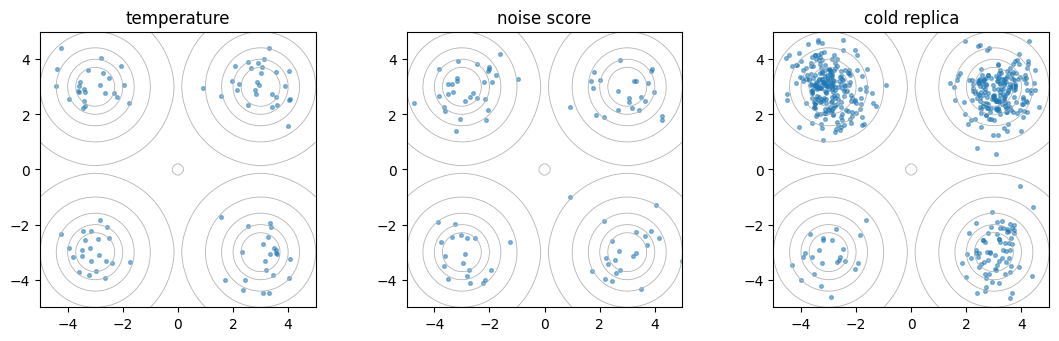

| workflow | mode0 | mode1 | mode2 | mode3 |
|---|---|---|---|---|
| temperature | 0.2292 | 0.25 | 0.2292 | 0.2917 |
| noise score | 0.2083 | 0.3125 | 0.2292 | 0.25 |
| cold replica | 0.04444 | 0.4481 | 0.1333 | 0.3741 |

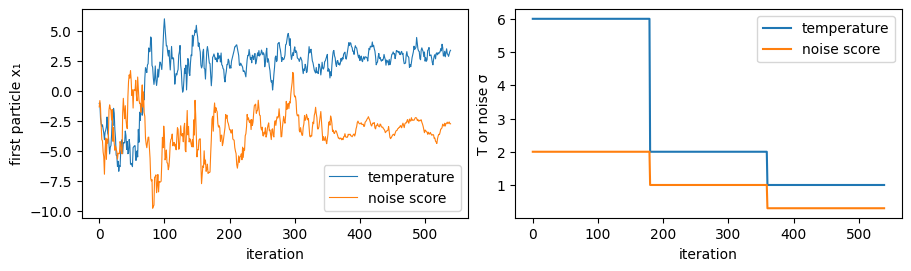

In [3]:
fig,ax=plt.subplots(1,3,figsize=(11,3.3),layout='constrained'); rows=[]
for a,(name,z) in zip(ax,endpoints.items()):
    contour(a,mixture); a.scatter(*cpu(z).T,s=7,alpha=.5); a.set_title(name)
    labels=(z[:,None]-mixture.means).square().sum(-1).argmin(-1)
    occupancy=torch.bincount(labels,minlength=4).double()/len(z)
    rows.append(dict(workflow=name,**{f'mode{k}':float(v) for k,v in enumerate(occupancy)}))
plt.show(); table(rows)
fig,ax=plt.subplots(1,2,figsize=(9,2.6),layout='constrained')
for name,tr in traces.items(): ax[0].plot(cpu(tr[:,0]),label=name,lw=.8); ax[1].plot(stages[name],label=name)
ax[0].set(xlabel='iteration',ylabel='first particle x₁'); ax[1].set(xlabel='iteration',ylabel='T or noise σ'); ax[0].legend(); ax[1].legend(); plt.show()

The score is the exact analytic Gaussian-convolved mixture score; this notebook does not train a score network. A finite noise schedule ends at a smoothed target, not an exact draw from the unsmoothed mixture. Endpoint ensembles and correlated cold-replica draws have different sampling units; their mode fractions are descriptive.

In [4]:
fixture=LatentGaussianLaplace(observations=[.2,.8,1.1,.4],noise_scale=.7,penalty=1.,device=device,dtype=dtype)
theta=tensor([-1.]); latent=torch.zeros((64,4),device=device,dtype=dtype)
models={'MYIPLA':MYIPLA(fixture.smooth_potential,fixture.prox_joint,theta,latent,.015,smoothing=.05,generator=gen(10)),
        'PIPULA':PIPULA(fixture.full_joint_prox,theta,latent,.015,generator=gen(11)),
        'PIPGLA':PIPGLA(fixture.smooth_potential,fixture.prox_joint,theta,latent,.015,generator=gen(12))}
learning_steps=450 if quick else 1400; curves={}; rows=[]
for name,m in models.items():
    vals=[]; sync(); start=time.perf_counter()
    for _ in range(learning_steps): vals.append(m.step().theta[0])
    sync(); curves[name]=torch.stack(vals)
    rows.append(dict(method=name,seconds=time.perf_counter()-start,final_theta=float(m.theta[0]),tail_mean_theta=float(curves[name][-100:].mean())))
grid=torch.linspace(-1,2,500,device=device,dtype=dtype)
ll=fixture.log_marginal_likelihood(grid[:,None]); mle=grid[ll.argmax()]
table(rows); print('Independent integrated-likelihood grid optimum:',float(mle))

| method | seconds | final_theta | tail_mean_theta |
|---|---|---|---|
| MYIPLA | 0.1787 | 0.6851 | 0.6104 |
| PIPULA | 0.1118 | 0.5914 | 0.5564 |
| PIPGLA | 0.1656 | 0.5181 | 0.6039 |

Independent integrated-likelihood grid optimum: 0.623246492985972


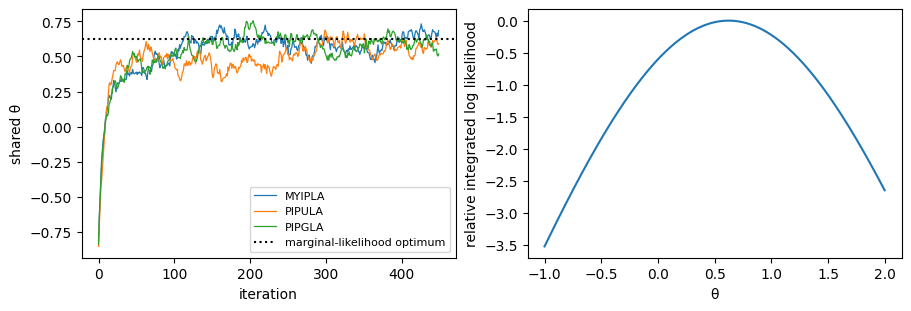

In [5]:
fig,ax=plt.subplots(1,2,figsize=(9,3),layout='constrained')
for name,v in curves.items(): ax[0].plot(cpu(v),label=name,lw=.9)
ax[0].axhline(float(mle),color='k',ls=':',label='marginal-likelihood optimum'); ax[0].set(xlabel='iteration',ylabel='shared θ'); ax[0].legend(fontsize=8)
ax[1].plot(cpu(grid),cpu(ll-ll.max())); ax[1].set(xlabel='θ',ylabel='relative integrated log likelihood'); plt.show()

The three proximal updates use the same Normal/Laplace latent model but different splitting and smoothing. PIPULA requires the full **joint** prox; using only soft thresholding would implement a different method. The fixture solves its scalar optimality equation piecewise analytically. Shared $\theta$ has noise variance $2h/N$: a finite ensemble learns a powered marginal and does not produce an ordinary Bayesian parameter posterior. No cross-task leaderboard is appropriate.